In [16]:
import torch
from rfdetr import RFDETRNano
# from rfdetr import RFDETRMedium
# from rfdetr import RFDETRLarge
# model = RFDETRNano()
# model = RFDETRMedium()
model = RFDETRNano(pretrain_weights="./v2/checkpoint_best_total.pth", resolution=448)


Using a different number of positional encodings than DINOv2, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Using patch size 16 instead of 14, which means we're not loading DINOv2 backbone weights. This is not a problem if finetuning a pretrained RF-DETR model.
Loading pretrain weights


In [17]:
model.optimize_for_inference()

In [18]:
from PIL import Image
import supervision as sv

image = Image.open("./rfdetr_dataset/valid/1478020224197266285.jpg")
detections = model.predict(image, threshold=0.25)

val_ds = sv.DetectionDataset.from_coco(
    images_directory_path="rfdetr_dataset/valid",
    annotations_path="rfdetr_dataset/valid/_annotations.coco.json"
)

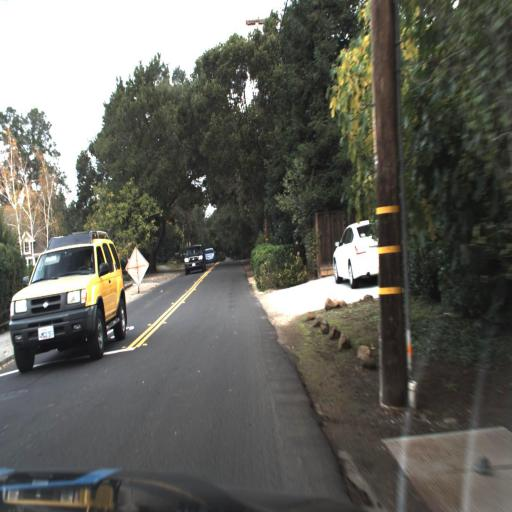

In [19]:
test_img = Image.open(val_ds[25][0])
test_img

In [20]:
import supervision as sv
from tqdm import tqdm
from supervision.metrics import MeanAveragePrecision

targets = []
predictions = []

for path, image, annotations in tqdm(val_ds):
    image = Image.open(path)
    detections = model.predict(image, threshold=0.5)

    targets.append(annotations)
    predictions.append(detections)

100%|██████████| 2250/2250 [02:50<00:00, 13.21it/s]


In [21]:
map_metric = MeanAveragePrecision()
map_result = map_metric.update(predictions, targets).compute()
print(map_result)

Average Precision (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.395
Average Precision (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.706
Average Precision (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.389
Average Precision (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.348
Average Precision (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.521
Average Precision (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.703


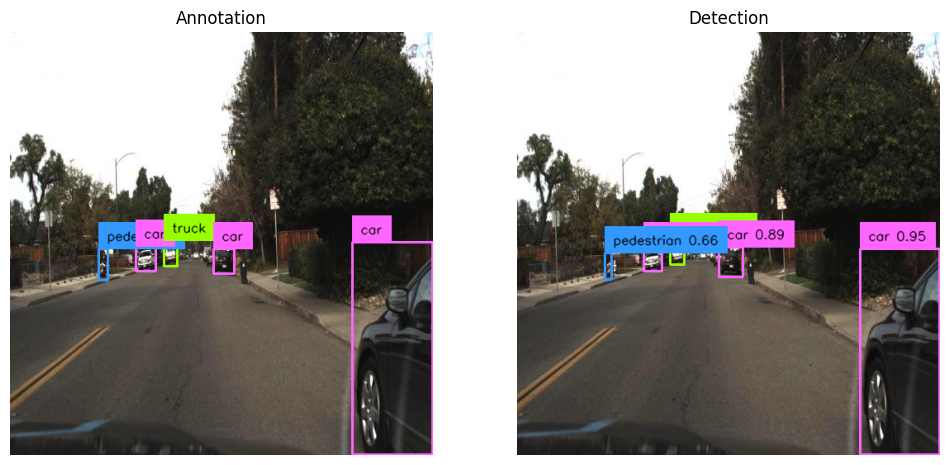

In [22]:
import supervision as sv
from PIL import Image

path, image, annotations = val_ds[110]
image = Image.open(path)

detections = model.predict(image, threshold=0.5)

text_scale = sv.calculate_optimal_text_scale(resolution_wh=image.size)
thickness = sv.calculate_optimal_line_thickness(resolution_wh=image.size)
color = sv.ColorPalette.from_hex([
    "#ffff00", "#ff9b00", "#ff66ff", "#3399ff", "#ff66b2", "#ff8080",
    "#b266ff", "#9999ff", "#66ffff", "#33ff99", "#66ff66", "#99ff00"
])

bbox_annotator = sv.BoxAnnotator(color=color,thickness=thickness)
label_annotator = sv.LabelAnnotator(
    color=color, 
    text_color=sv.Color.BLACK,
    text_scale=text_scale)

annotations_labels = [
    f"{val_ds.classes[class_id]}"
    for class_id
    in annotations.class_id
]

detections_labels = [
    f"{val_ds.classes[class_id]} {confidence:.2f}"
    for class_id, confidence
    in zip(detections.class_id, detections.confidence)
]

annotation_image = image.copy()
annotation_image = bbox_annotator.annotate(annotation_image, annotations)
annotation_image = label_annotator.annotate(annotation_image, annotations, annotations_labels)

detections_image = image.copy()
detections_image = bbox_annotator.annotate(detections_image, detections)
detections_image = label_annotator.annotate(detections_image, detections, detections_labels)

sv.plot_images_grid(images=[annotation_image, detections_image], grid_size=(1, 2), titles=["Annotation", "Detection"])

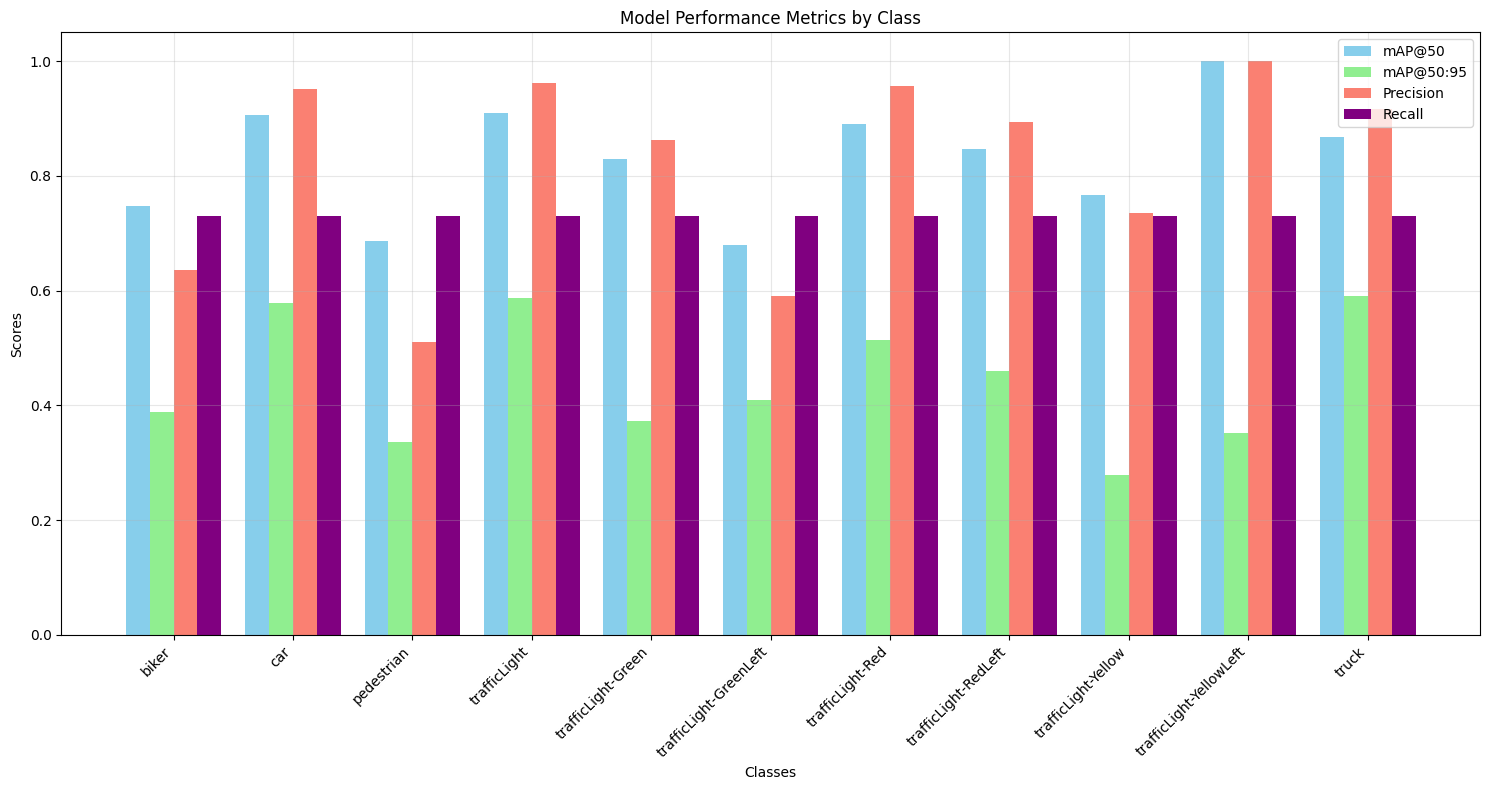

In [23]:
import json
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the results
with open('v2/results.json', 'r') as f:
    results = json.load(f)

# Extract validation results
valid_results = results['class_map']['valid']

# Create a DataFrame
data = []
for item in valid_results:
    if item['class'] != 'all':  # Exclude the 'all' summary row
        data.append({
            'class': item['class'],
            'mAP@50': item['map@50'],
            'mAP@50:95': item['map@50:95'],
            'Precision': item['precision'],
            'Recall': item['recall']
        })

df = pd.DataFrame(data)

# Create the visualization
plt.figure(figsize=(15, 8))
x = range(len(df['class']))

# Plot bars
width = 0.2
plt.bar(x, df['mAP@50'], width, label='mAP@50', color='skyblue')
plt.bar([i + width for i in x], df['mAP@50:95'], width, label='mAP@50:95', color='lightgreen')
plt.bar([i + width * 2 for i in x], df['Precision'], width, label='Precision', color='salmon')
plt.bar([i + width * 3 for i in x], df['Recall'], width, label='Recall', color='purple')

# Customize the plot
plt.xlabel('Classes')
plt.ylabel('Scores')
plt.title('Model Performance Metrics by Class')
plt.xticks([i + width * 1.5 for i in x], df['class'], rotation=45, ha='right')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

Confusion matrix (rows=targets, cols=predictions):
[[0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00]
 [0.000e+00 1.590e+02 0.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 1.050e+02]
 [0.000e+00 0.000e+00 7.421e+03 2.000e+00 0.000e+00 0.000e+00 0.000e+00
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 4.000e+01 2.061e+03]
 [0.000e+00 1.000e+00 3.000e+00 8.000e+02 0.000e+00 0.000e+00 0.000e+00
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 8.230e+02]
 [0.000e+00 0.000e+00 0.000e+00 0.000e+00 3.090e+02 3.000e+00 2.000e+00
  7.000e+00 1.000e+00 0.000e+00 0.000e+00 0.000e+00 4.800e+01]
 [0.000e+00 0.000e+00 0.000e+00 0.000e+00 6.000e+00 5.350e+02 2.000e+00
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 2.450e+02]
 [0.000e+00 0.000e+00 0.000e+00 0.000e+00 1.000e+01 0.000e+00 3.100e+01
  0.000e+00 0.000e+00 0.000e+00 0.000e+00 0.000e+00 2.200e+01]
 [0.

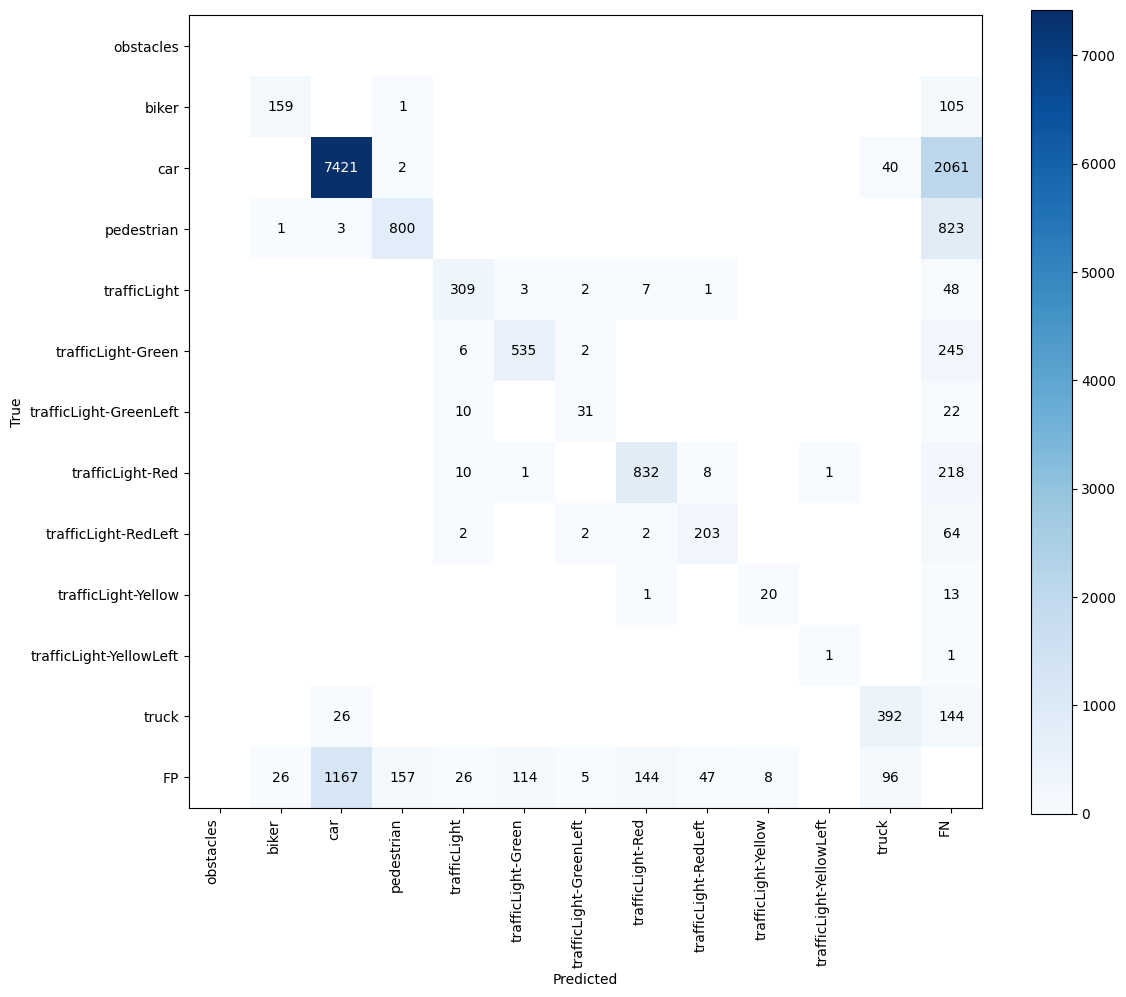

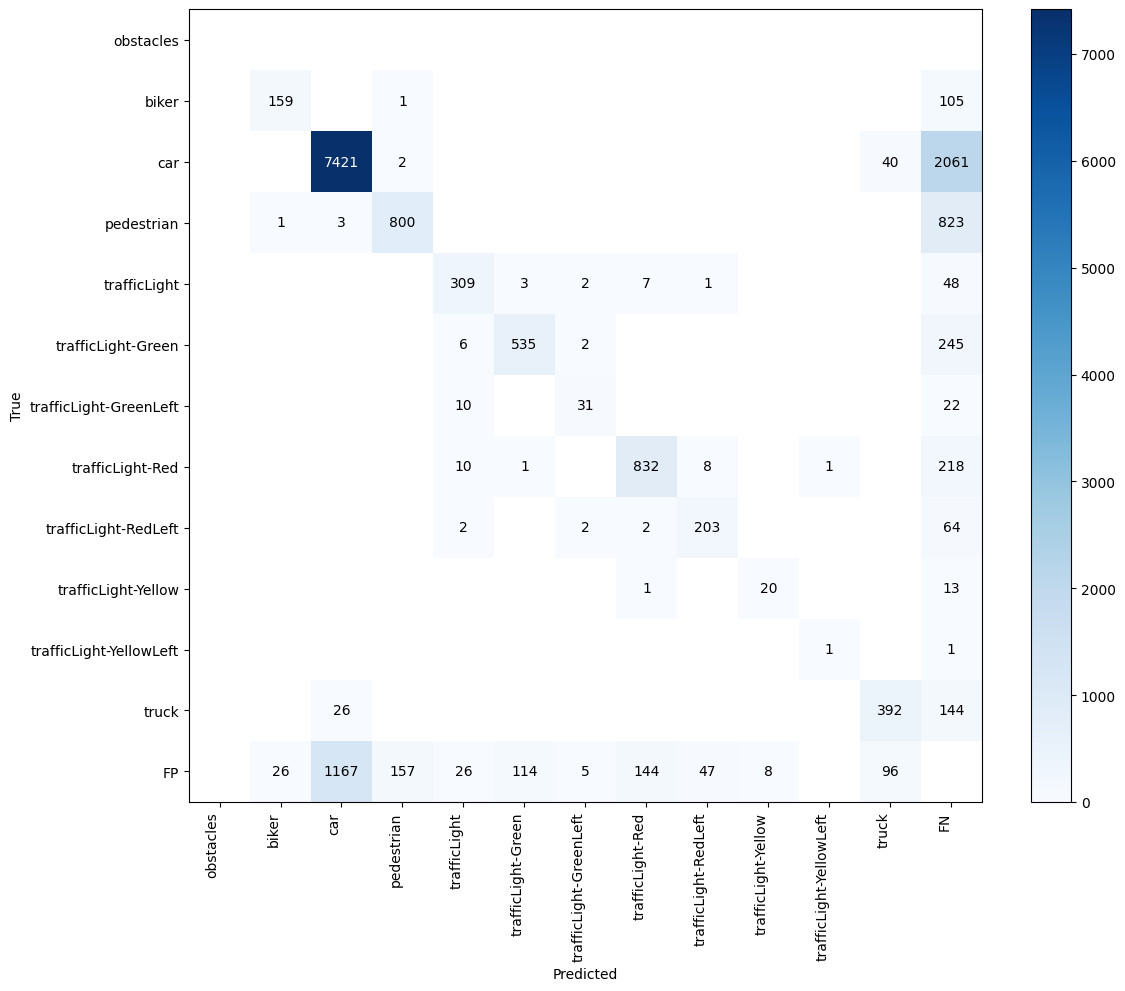

In [24]:
import supervision as sv
from PIL import Image
from tqdm import tqdm

# If predictions/targets were built earlier in the notebook, reuse them.
# Otherwise recompute them here to ensure consistent data.
try:
    assert len(predictions) == len(targets) and len(predictions) > 0
except Exception:
    predictions = []
    targets = []
    for path, _, annotations in tqdm(val_ds, desc="Building preds/targets"):
        image = Image.open(path)
        detections = model.predict(image, threshold=0.5)  # adjust threshold as needed
        predictions.append(detections)
        targets.append(annotations)

# Build confusion matrix from detections
confusion_matrix = sv.ConfusionMatrix.from_detections(
    predictions=predictions,
    targets=targets,
    classes=val_ds.classes
)

# Inspect and plot
print("Confusion matrix (rows=targets, cols=predictions):")
print(confusion_matrix.matrix)
confusion_matrix.plot()

In [25]:
# ...existing code...
import time
import numpy as np
from PIL import Image
import torch

def measure_fps_across_dataset(model, val_ds, predictions=None, targets=None,
                               max_images=30, runs_per_image=20, warmup_per_image=3, threshold=0.5):
    # decide which indices to test
    if predictions is not None and len(predictions) > 0:
        n = len(predictions)
        idxs = np.linspace(0, n - 1, num=min(max_images, n), dtype=int)
    else:
        n = len(val_ds)
        idxs = np.linspace(0, n - 1, num=min(max_images, n), dtype=int)

    times = []
    gpu = torch.cuda.is_available()

    for i in idxs:
        path, _, _ = val_ds[i]  # val_ds yields (path, image_placeholder, annotations)
        image = Image.open(path)

        # warmup for this image
        for _ in range(warmup_per_image):
            _ = model.predict(image, threshold=threshold)
        if gpu:
            torch.cuda.synchronize()

        # timed runs
        for _ in range(runs_per_image):
            t0 = time.perf_counter()
            _ = model.predict(image, threshold=threshold)
            if gpu:
                torch.cuda.synchronize()
            t1 = time.perf_counter()
            times.append(t1 - t0)

    times = np.array(times)
    total_calls = len(times)
    total_time = times.sum()
    fps = total_calls / total_time if total_time > 0 else float('nan')

    return {
        "num_images_sampled": len(idxs),
        "runs_per_image": runs_per_image,
        "total_calls": total_calls,
        "fps": fps,
        "mean_ms": times.mean() * 1000,
        "median_ms": np.median(times) * 1000,
        "std_ms": times.std() * 1000,
        "total_time_s": total_time
    }

# try to reuse existing predictions/targets if available
try:
    preds = predictions
    targs = targets
except NameError:
    preds = None
    targs = None

result = measure_fps_across_dataset(model, val_ds, predictions=preds, targets=targs,
                                    max_images=30, runs_per_image=20, warmup_per_image=3, threshold=0.5)
print(result)
# ...existing code...

{'num_images_sampled': 30, 'runs_per_image': 20, 'total_calls': 600, 'fps': np.float64(13.485969497621761), 'mean_ms': np.float64(74.15113909136078), 'median_ms': np.float64(74.10925001022406), 'std_ms': np.float64(4.004600365481301), 'total_time_s': np.float64(44.49068345481646)}
